# Etap 4 — Analiza: jak OZE zmieniają polski system energetyczny

Dane: hurtownia dbt (`marts.fct_energia_godzinowa`, `marts.fct_bilans_dzienny`),
czerwiec 2024 – październik 2026, ponad 20 tys. pełnych godzin.

Pytania biznesowe:
1. Jak szybko rośnie udział wiatru i słońca w pokryciu zapotrzebowania?
2. Jak często OZE pokrywają ponad połowę zapotrzebowania i kiedy to się dzieje?
3. Co to oznacza dla elektrowni konwencjonalnych (zapotrzebowanie rezydualne, „kaczka”)?
4. Od czego zależy zapotrzebowanie: temperatura, dzień tygodnia, święta?
5. Które dane pogodowe najlepiej tłumaczą generację (wskazówki dla modelu z etapu 5)?

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

BAZA = Path("..") / "data" / "energia.duckdb"
con = duckdb.connect(str(BAZA), read_only=True)
con.execute("set TimeZone = 'UTC'")


def sql(zapytanie: str) -> pd.DataFrame:
    return con.sql(zapytanie).df()


# Paleta zwalidowana pod kątem daltonizmu i kontrastu (ta sama co w aplikacji, wariant jasny)
KOLOR = {"zapotrzebowanie": "#14212b", "rezydualne": "#2a78d6", "wiatr": "#1baf7a", "pv": "#eda100"}
LATA = {2024: "#9ec5f4", 2025: "#5598e7", 2026: "#1c5cab"}  # jeden odcień, jaśniej = dawniej

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e9ec", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#c9d1d8", "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

## 1. Udział OZE rośnie: porównanie tych samych miesięcy rok do roku

Porównujemy lipiec–wrzesień, bo ten okres jest w danych dla każdego roku
(dane zaczynają się w czerwcu 2024). Porównanie całych lat byłoby nieuczciwe:
zima ma dużo mniej słońca.

In [2]:
rdr = sql("""
    select year(data) as rok,
           sum(wiatr_gwh + pv_gwh) / sum(zapotrzebowanie_gwh) as udzial_oze,
           sum(pv_gwh) as pv_gwh, sum(wiatr_gwh) as wiatr_gwh, sum(zapotrzebowanie_gwh) as zapotrzebowanie_gwh
    from marts.fct_bilans_dzienny where miesiac in (7, 8, 9)
    group by 1 order by 1
""")
rdr.style.format({"udzial_oze": "{:.1%}", "pv_gwh": "{:,.0f}", "wiatr_gwh": "{:,.0f}", "zapotrzebowanie_gwh": "{:,.0f}"})

,rok,udzial_oze,pv_gwh,wiatr_gwh,zapotrzebowanie_gwh
0,2024,29.0%,"6,609","4,425","38,096"
1,2025,29.4%,"6,753","4,208","37,300"
2,2026,35.2%,"7,957","5,443","38,033"


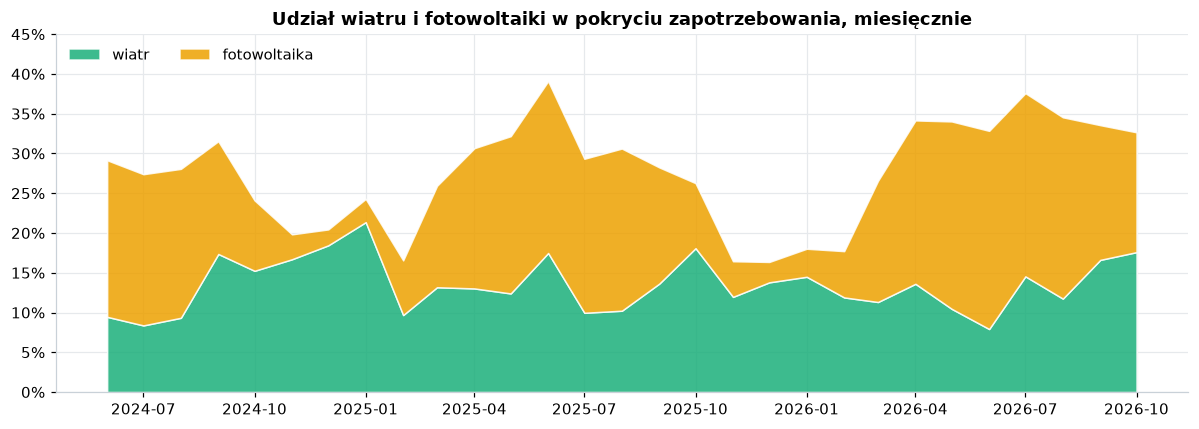

In [3]:
mies = sql("""
    select date_trunc('month', data) as miesiac,
           sum(wiatr_gwh) / sum(zapotrzebowanie_gwh) as wiatr,
           sum(pv_gwh) / sum(zapotrzebowanie_gwh) as pv
    from marts.fct_bilans_dzienny group by 1 order by 1
""").set_index("miesiac")

fig, ax = plt.subplots(figsize=(11, 4))
ax.stackplot(mies.index, mies["wiatr"], mies["pv"], colors=[KOLOR["wiatr"], KOLOR["pv"]],
             labels=["wiatr", "fotowoltaika"], alpha=0.85, edgecolor="white", linewidth=1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("Udział wiatru i fotowoltaiki w pokryciu zapotrzebowania, miesięcznie")
ax.legend(loc="upper left", frameon=False, ncols=2)
ax.set_ylim(0, 0.45)
plt.tight_layout()

**Wniosek.** W lipcu–wrześniu udział wiatru i PV wzrósł z **29,0% (2024)** przez 29,4% (2025)
do **35,2% (2026)**, przy praktycznie niezmienionym zapotrzebowaniu (~38 TWh w kwartale).
Wzrost w 2026 to efekt obu źródeł: PV +18%, wiatr +29% rok do roku.
Sezonowość jest wyraźna: latem dominuje PV (ponad 20% zapotrzebowania), zimą wiatr,
a najsłabsze są listopad–luty (16–18% w ostatnim sezonie).

## 2. Godziny, w których OZE pokrywają ponad połowę zapotrzebowania

In [4]:
ponad50 = sql("""
    select year(czas_lokalny) as rok,
           count(*) filter (where udzial_oze > 0.5) as godzin_ponad_50,
           count(*) filter (where udzial_oze > 0.8) as godzin_ponad_80,
           max(udzial_oze) as rekord
    from marts.fct_energia_godzinowa where miesiac between 6 and 9
    group by 1 order by 1
""")
ponad50.style.format({"rekord": "{:.1%}"})

,rok,godzin_ponad_50,godzin_ponad_80,rekord
0,2024,420,1,80.6%
1,2025,650,3,85.3%
2,2026,804,10,86.4%


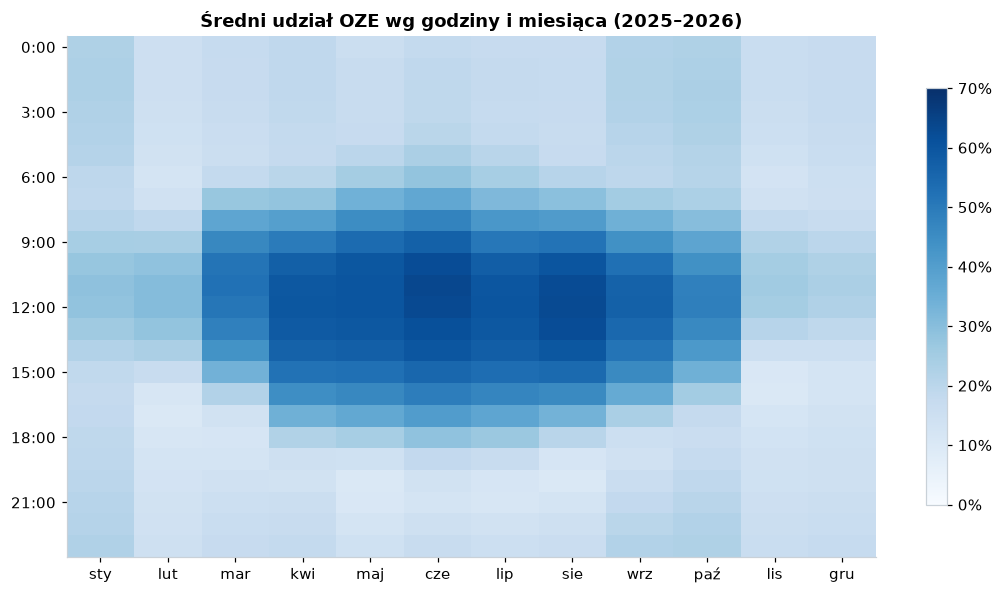

In [5]:
mapa = sql("""
    select miesiac, godzina, avg(udzial_oze) as udzial
    from marts.fct_energia_godzinowa where year(czas_lokalny) >= 2025
    group by 1, 2
""").pivot(index="godzina", columns="miesiac", values="udzial")

fig, ax = plt.subplots(figsize=(10, 5.5))
obraz = ax.imshow(mapa, aspect="auto", cmap="Blues", vmin=0, vmax=0.7, origin="upper")
ax.set_xticks(range(12), ["sty", "lut", "mar", "kwi", "maj", "cze", "lip", "sie", "wrz", "paź", "lis", "gru"])
ax.set_yticks(range(0, 24, 3), [f"{h}:00" for h in range(0, 24, 3)])
ax.grid(False)
ax.set_title("Średni udział OZE wg godziny i miesiąca (2025–2026)")
fig.colorbar(obraz, ax=ax, format=mtick.PercentFormatter(1.0, decimals=0), shrink=0.8)
plt.tight_layout()

**Wniosek.** W sezonie czerwiec–wrzesień liczba godzin z udziałem OZE powyżej 50% wzrosła
z **420 (2024)** do **650 (2025)** i **804 (2026)**, czyli prawie dwukrotnie w dwa lata.
Rekord to **86,4%** (28.08.2026, 12:00). To niemal wyłącznie godziny 10–15 od kwietnia
do września: o udziale decyduje słońce, wiatr podbija wynik tylko w niektóre dni.

## 3. „Kaczka”: zapotrzebowanie rezydualne w letni dzień roboczy

Zapotrzebowanie rezydualne = zapotrzebowanie − wiatr − PV, czyli to, co muszą pokryć
elektrownie konwencjonalne, magazyny i import. Kształt profilu dobowego przypomina kaczkę
(*duck curve*, pojęcie z Kalifornii): głęboki brzuch w południe i wysoka szyja wieczorem.

,południe 11–13 (GW),wieczór 19–20 (GW),rampa (GW)
rok,,,
2024,9.8,18.3,8.5
2025,8.0,17.3,9.3
2026,7.3,17.5,10.3


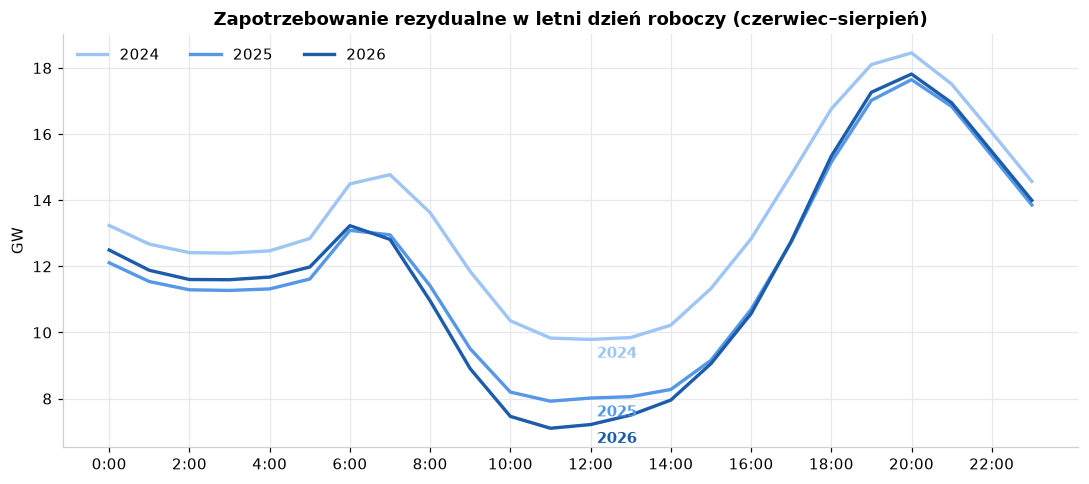

In [6]:
kaczka = sql("""
    select year(czas_lokalny) as rok, godzina, avg(rezydualne_mw) as rezydualne
    from marts.fct_energia_godzinowa
    where miesiac in (6, 7, 8) and czy_dzien_roboczy
    group by 1, 2 order by 1, 2
""").pivot(index="godzina", columns="rok", values="rezydualne")

fig, ax = plt.subplots(figsize=(10, 4.5))
for rok, kolor in LATA.items():
    ax.plot(kaczka.index, kaczka[rok] / 1000, color=kolor, linewidth=2.2, label=str(rok))
    ax.annotate(str(rok), (12, kaczka.loc[12, rok] / 1000), xytext=(4, -12), textcoords="offset points",
                color=kolor, fontweight="bold")
ax.set_xticks(range(0, 24, 2), [f"{h}:00" for h in range(0, 24, 2)])
ax.set_ylabel("GW")
ax.set_title("Zapotrzebowanie rezydualne w letni dzień roboczy (czerwiec–sierpień)")
ax.legend(frameon=False, ncols=3)
plt.tight_layout()

zestawienie = pd.DataFrame({
    "południe 11–13 (GW)": kaczka.loc[11:13].mean() / 1000,
    "wieczór 19–20 (GW)": kaczka.loc[19:20].mean() / 1000,
})
zestawienie["rampa (GW)"] = zestawienie["wieczór 19–20 (GW)"] - zestawienie["południe 11–13 (GW)"]
zestawienie.round(1)

**Wniosek.** W letnie dni robocze zapotrzebowanie rezydualne w południe spadło z **9,8 GW (2024)**
do **7,3 GW (2026)**, a wieczorem pozostaje na poziomie ~17,5 GW. Między południem a wieczorem
elektrownie konwencjonalne, magazyny i import muszą więc dołożyć **ok. 10 GW w ok. 8 godzin**
(z ~12:00 do 20:00), a ta rampa rośnie z każdym rokiem: **8,5 → 9,3 → 10,3 GW**.

Ekstremum: **Wielkanoc 2026 (5.04, 11:00)**: zapotrzebowanie 12,9 GW, PV 9,4 GW,
rezydualne tylko **2,5 GW**. Święto i słońce naraz to najtrudniejszy moment dla bilansowania
systemu. Ten dzień musi znać model (kalendarz świąt jest w `dim_czas`).

## 4. Od czego zależy zapotrzebowanie

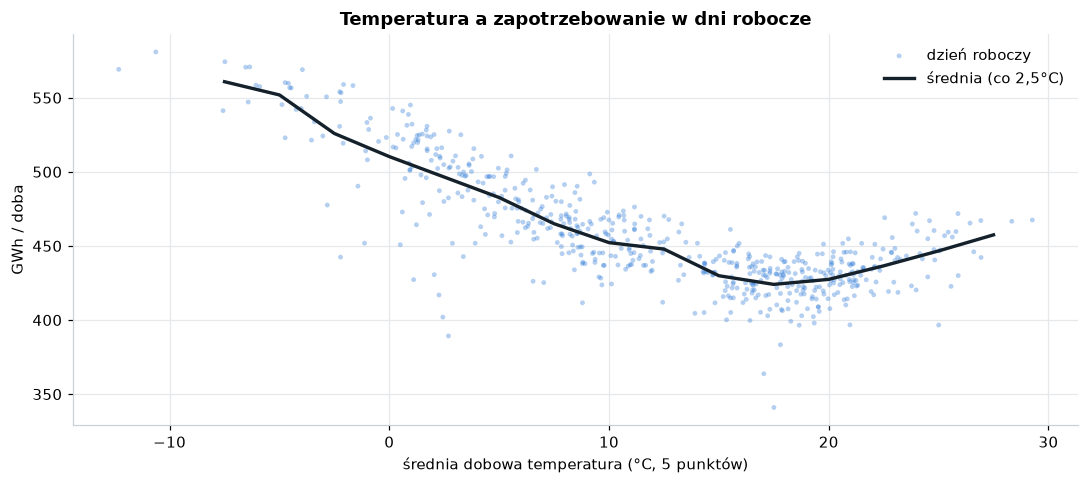

In [7]:
temp = sql("""
    select temperatura_srednia_c, zapotrzebowanie_gwh, czy_dzien_roboczy
    from marts.fct_bilans_dzienny
""")
robocze = temp[temp["czy_dzien_roboczy"]]
koszyki = robocze.groupby((robocze["temperatura_srednia_c"] / 2.5).round() * 2.5)["zapotrzebowanie_gwh"].agg(["mean", "count"])
koszyki = koszyki[koszyki["count"] >= 5]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(robocze["temperatura_srednia_c"], robocze["zapotrzebowanie_gwh"], s=10, alpha=0.35,
           color=KOLOR["rezydualne"], edgecolors="none", label="dzień roboczy")
ax.plot(koszyki.index, koszyki["mean"], color=KOLOR["zapotrzebowanie"], linewidth=2.2, label="średnia (co 2,5°C)")
ax.set_xlabel("średnia dobowa temperatura (°C, 5 punktów)")
ax.set_ylabel("GWh / doba")
ax.set_title("Temperatura a zapotrzebowanie w dni robocze")
ax.legend(frameon=False)
plt.tight_layout()

In [8]:
typ = sql("""
    select d.typ_dnia, count(*) as dni,
           avg(b.zapotrzebowanie_gwh) as srednio_gwh, avg(b.szczyt_zapotrzebowania_mw) as szczyt_mw
    from marts.fct_bilans_dzienny b join marts.dim_data d using (data)
    group by 1 order by 3 desc
""")
typ["vs dzień roboczy"] = typ["srednio_gwh"] / typ["srednio_gwh"].iloc[0] - 1
typ.style.format({"srednio_gwh": "{:.0f}", "szczyt_mw": "{:,.0f}", "vs dzień roboczy": "{:+.0%}"})

,typ_dnia,dni,srednio_gwh,szczyt_mw,vs dzień roboczy
0,dzień roboczy,586,457,"21,751",+0%
1,sobota,119,408,"18,981",-11%
2,niedziela i święto,145,369,"17,619",-19%


**Wniosek.** Zależność od temperatury ma kształt litery **U** z minimum przy ok. **18–20°C**
(~427 GWh na dobę roboczą). W najzimniejsze dni (−8 do −10°C) zapotrzebowanie jest wyższe o ok. **32%** (ogrzewanie),
a przy 25–30°C rośnie ponownie o kilka procent (klimatyzacja). Zależność jest nieliniowa,
więc w modelu lepiej sprawdzi się model drzewiasty niż regresja liniowa.

Typ dnia ma podobnie duży wpływ: sobota **−11%**, niedziela i święto **−19%** względem dnia
roboczego. Model musi więc znać dzień tygodnia i kalendarz świąt.

## 5. Które dane pogodowe najlepiej tłumaczą generację

In [9]:
korelacje = sql("""
    select 'wiatr' as zrodlo, 'średnia z 5 punktów' as cecha, corr(wiatr_mw, wiatr_100m_sredni_kmh) as korelacja from marts.fct_energia_godzinowa
    union all select 'wiatr', 'Wielkopolska', corr(wiatr_mw, wiatr_wielkopolska_kmh) from marts.fct_energia_godzinowa
    union all select 'wiatr', 'Pomorze', corr(wiatr_mw, wiatr_pomorze_kmh) from marts.fct_energia_godzinowa
    union all select 'wiatr', 'Lubelskie', corr(wiatr_mw, wiatr_lubelskie_kmh) from marts.fct_energia_godzinowa
    union all select 'PV', 'średnia z 5 punktów', corr(pv_mw, promieniowanie_srednie_wm2) from marts.fct_energia_godzinowa
    union all select 'PV', 'Wielkopolska', corr(pv_mw, promieniowanie_wielkopolska_wm2) from marts.fct_energia_godzinowa
    union all select 'PV', 'Śląsk', corr(pv_mw, promieniowanie_slask_wm2) from marts.fct_energia_godzinowa
    union all select 'PV', 'Lubelskie', corr(pv_mw, promieniowanie_lubelskie_wm2) from marts.fct_energia_godzinowa
""")
korelacje.style.format({"korelacja": "{:.3f}"})

,zrodlo,cecha,korelacja
0,wiatr,średnia z 5 punktów,0.901
1,wiatr,Wielkopolska,0.828
2,wiatr,Pomorze,0.797
3,wiatr,Lubelskie,0.605
4,PV,średnia z 5 punktów,0.964
5,PV,Wielkopolska,0.933
6,PV,Śląsk,0.899
7,PV,Lubelskie,0.895


**Wniosek.** Średnia z kilku punktów tłumaczy generację lepiej niż którykolwiek pojedynczy
punkt (wiatr: **0,90** wobec 0,61–0,83; PV: **0,96** wobec 0,90–0,93). Farmy i panele są
rozproszone po kraju, a pojedynczy punkt łapie lokalną pogodę. Wskazówka na etap 5:
dać modelowi zarówno średnie, jak i poszczególne regiony, a w przyszłości rozważyć więcej punktów.

## Podsumowanie dla biznesu

| | |
|---|---|
| Udział wiatru i PV (lip–wrz) | 29,0% → 29,4% → **35,2%** (2024 → 2026) |
| Godziny z OZE > 50% (cze–wrz) | 420 → 650 → **804** |
| Rezydualne w letnie południe | 9,8 → 8,0 → **7,3 GW**, wieczór ~17,5 GW, rampa 8,5 → **10,3 GW** |
| Najtrudniejsza godzina | Wielkanoc 2026, 11:00: rezydualne **2,5 GW** |
| Wpływ temperatury | U-kształt, minimum ~18–20°C, mróz (−8 do −10°C): **+32%** |
| Wpływ typu dnia | sobota **−11%**, niedziela/święto **−19%** |
| Rekordy | PV **14,4 GW** (26.06.2026), wiatr **8,9 GW** (1.01.2025) |

Rosnąca rampa wieczorna i coraz głębsze południowe minimum to argument za magazynami energii
i elastycznymi elektrowniami, a dla nas za dobrą prognozą godzinową: im większy udział OZE,
tym droższy jest błąd prognozy generacji.